# Redesign in Math 1401

In [2]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import seaborn as sns
import scipy.stats as stats
from scipy.stats import gaussian_kde
import warnings
warnings.filterwarnings("ignore")

N = make_array(67, 65, 66, 63, 60, 62, 64, 68, 71, 69, 65, 62, 59, 58, 61,
               63, 66, 62, 59, 57, 55, 58, 60, 63, 62, 58, 56, 54, 57, 59)
pers = Table.read_table('http://faculty.ung.edu/rsinn/personality.csv')
births = Table.read_table('https://faculty.ung.edu/rsinn/data/baby.csv')
penicillin = Table.read_table("Penicillin measurements.csv")
pen = penicillin.relabel(1, "E. coli").relabel(2, "S. epidermidis").relabel(0,"Compound")

In [3]:
def describe(data, var = None):
  if isinstance(data, Table):
    data = data.column(var)
  names = np.array(["mean", "std", "n", "min", "Q1", "med", "Q3", "max", "IQR"])
  values = np.array([round(np.mean(data),1), round(stats.tstd(data),2), len(data) - 1, min(data), np.percentile(data, 25), np.median(data), np.percentile(data, 75), max(data), stats.iqr(data)])
  tab = Table().with_columns('Names', names, 'Values', values)
  transposed_tab = Table().with_columns( zip(tab.column('Names'), tab.column('Values')) ).show()
  return

def describes(data, num, group):
  dat = data.column(num)
  group_var = data.column(group)
  groups = np.unique(group_var)  ;  rows = []
  tab = Table(["group", "mean", "std", "n", "min", "Q1", "med", "Q3", "max", "IQR"])
  for g in groups:
    # Filter data for the current group
    sub_dat = dat[group_var == g]
    rows = [g, round(np.mean(sub_dat), 1), round(stats.tstd(sub_dat), 2), len(sub_dat) - 1, min(sub_dat), np.percentile(sub_dat, 25), np.median(sub_dat), np.percentile(sub_dat, 75), max(sub_dat), stats.iqr(sub_dat)]        
    tab = tab.with_row(rows)
  tab.show()
  return 

def box(data, num = None, sm = False):
  if isinstance(data, Table):
    df = data.to_df()
    sns.boxplot(data=df, y=num, width=0.45, showmeans=sm)  ;
    plots.title(f'Boxplot of {num}')
    plots.xticks([], [])
    plots.show()  
  else:
    if num == True:
      sm = True  ;  num = 'Variable'
    if num == None:
      num = 'Variable'
    plots.figure(figsize=(6, 5))
    sns.boxplot(data, width=0.45, showmeans=sm)  ;
    plots.title(f'Boxplot of {num}')
    plots.xticks([], [])
    plots.show()  
  return

def boxes(tab, num = None, cat = None, sm = False):
# Dictionary for median line styling (blue) and mean marker styling (golden triangle)
  median_props = { "color": "darkblue", "linewidth": 0.75 } ; mean_props = { "marker": "^", "markerfacecolor": "gold", "markeredgecolor": "black", "markersize": 7 }
  sns.set_theme(style="darkgrid")
  plots.figure(figsize=(8, 7))
  if isinstance(tab, Table):
    df = tab.to_df()
    n_categories = df[cat].nunique()
    max_label_length = df[cat].astype(str).str.len().max()
    rot = 45 if n_categories > 5 or max_label_length > 10 else 0
    sns.boxplot(data=tab, x=cat, y=num, width=0.75, showmeans=sm, medianprops=median_props, meanprops=mean_props)
    plots.xticks(rotation=rot, ha="right" if rot > 0 else "center")
    plots.title(f'Boxplot of {num} Grouped by {cat}')
    plots.show()
  else:
    arrays = list(tab.values()) ; labels = list(tab.keys())
    sns.set_theme(style="darkgrid")
    sns.boxplot( data=arrays, color="#1f77b4", width=0.75, showmeans=sm, medianprops=median_props, meanprops=mean_props)
    rot = 45 if len(arrays) > 5 else 0
    plots.xticks(ticks=range(len(labels)), labels=labels, rotation=rot)
    title_str = num if isinstance(num, str) else "Arrays"
    plots.title(f'Boxplot of {title_str}')
    plots.show() 
  return

def density(data, num = None):
  if isinstance(data, Table):
    sns.kdeplot( data = data.column(num), bw_method="scott", bw_adjust=0.75, cut=3 )
    plots.title(f'Density Plot of {num}')
    plots.show()
  else:
    if num == None:
      num = 'Variable'
      sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )
      plots.title(f'Density Plot of {num}')
      plots.show()
    else:
      sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
  return

def densities(tab, var, group_var):
  groups = tab.column(group_var)
  unique_groups = np.unique(groups)  ;  plots.figure()
  for g in unique_groups:
    # Filter data for the current group
    mask = (groups == g)
    x = tab.column(var)[mask]   
    # Calculate KDE for the group subset
    kde = gaussian_kde(x)
    x_grid = np.linspace(x.min() - 1, x.max() + 1, 512)  ;    plots.plot(x_grid, kde(x_grid), label=str(g))   
  plots.title(f'Density Plot of {var} by {group_var}')  ;  plots.xlabel(f'{var}')  ;  plots.ylabel('Density')
  plots.legend()  ;  plots.show()
  return

In [4]:
describe(N)

mean,std,n,min,Q1,med,Q3,max,IQR
61.6,4.26,29,54,58.25,62,64.75,71,6.5


In [5]:
describes(pers,'Perf','SitClass')

group,mean,std,n,min,Q1,med,Q3,max,IQR
B,103.8,16.47,27,73,91.75,102,119.25,130,27.5
F,114.2,18.11,44,78,101,113,128,154,27
M,105.9,15.89,55,49,96.75,107,114,137,17.25


In [6]:
describes(births,'Birth Weight','Maternal Smoker')

group,mean,std,n,min,Q1,med,Q3,max,IQR
False,123.1,17.42,714,55,113,123,134,176,21
True,113.8,18.3,458,58,101,115,126,163,25


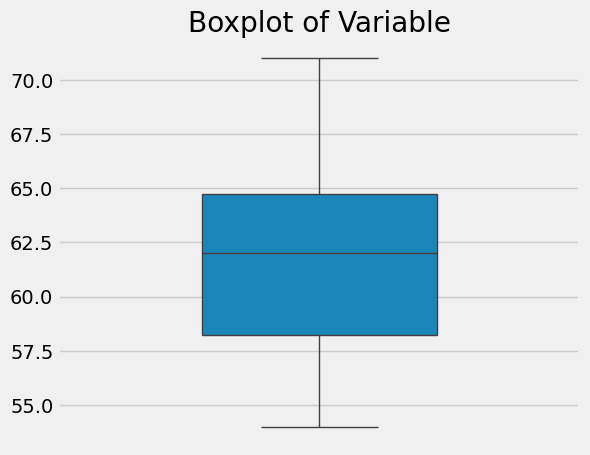

In [9]:
box(N)

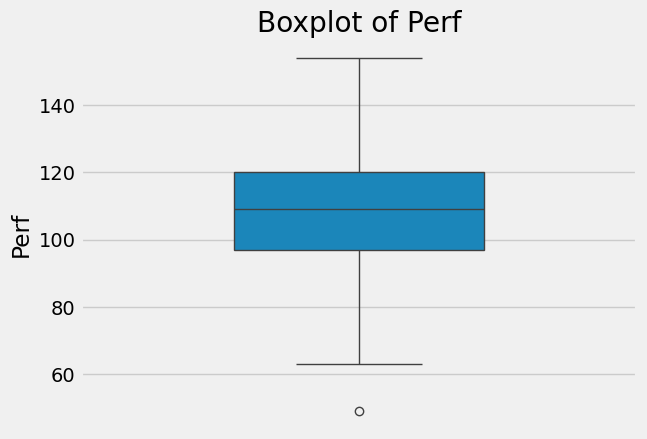

In [10]:
box(pers,'Perf')

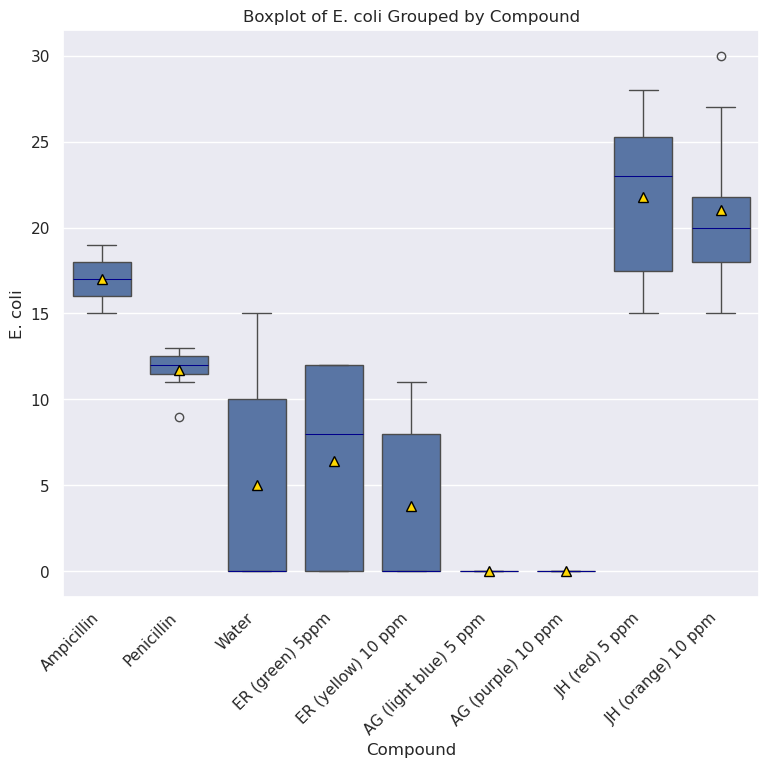

In [11]:
boxes(pen, 'E. coli','Compound', True)

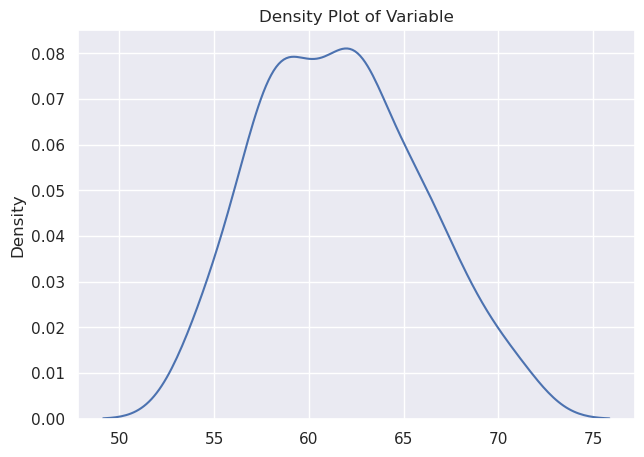

In [12]:
density(N)

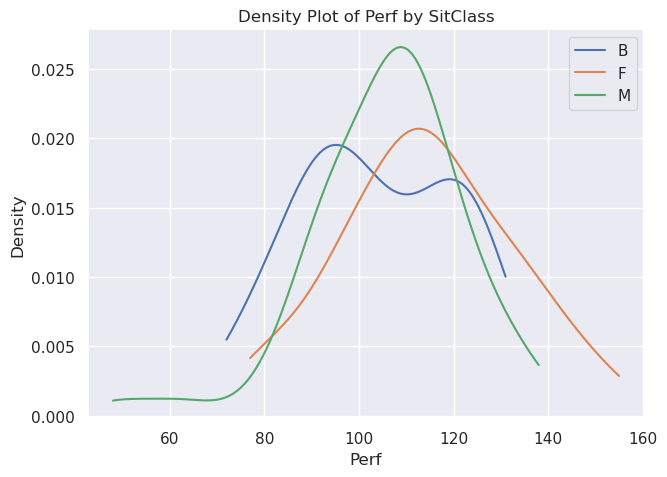

In [13]:
densities(pers,"Perf","SitClass")